In [1]:
import hoomd
import gsd.hoomd
import matplotlib.pyplot as plt
import numpy as np
from hoomd.vbc_plugin import vbc_potential
# from hoomd.md import 

In [2]:
# from hoomd.azplugins import pair

In [27]:
nlist = hoomd.md.nlist.Tree(buffer=0.0, exclusions=('bond',))

In [28]:
# nlist

In [29]:
# ph = pair.Hertz(nlist)

In [30]:
vbc = vbc_potential.VBC(nlist, default_r_cut=2.0)

In [31]:
# a = 10.0
# b = 10.0
# c = 1.0

vbc.params[('A', 'A')] = dict(A=2.0, B=-2.0,attr_rcut=1.5, rep_rcut=1.0, density_rcut=2.0, ncut_ij=1.0, ncut_ji=1.0)
# vbc.params[('B', 'B')] = dict(A=a, B=b)
# vbc.params[('A', 'A')] = dict(A=a, B=b)

In [32]:
snapshot = gsd.hoomd.Frame()

# Place a polymer in the box.
N = 12
snapshot.particles.N = N
snapshot.particles.position = np.random.randint(-3,3,size=(N,3)) + np.random.randn(N,3)
snapshot.particles.types = ['A']
snapshot.particles.typeid = ([0] * (N//2)) + ([0] * (N//2))
snapshot.configuration.box = [10, 10, 10, 0, 0, 0]

# Connect particles with bonds.
snapshot.bonds.N = N-1
snapshot.bonds.types = ['A-A']
snapshot.bonds.typeid = [0] * (N-1)
snapshot.bonds.group = np.dstack((np.arange(0,N-1),np.arange(1,N)))

with gsd.hoomd.open(name='molecular.gsd', mode='w') as f:
    f.append(snapshot)

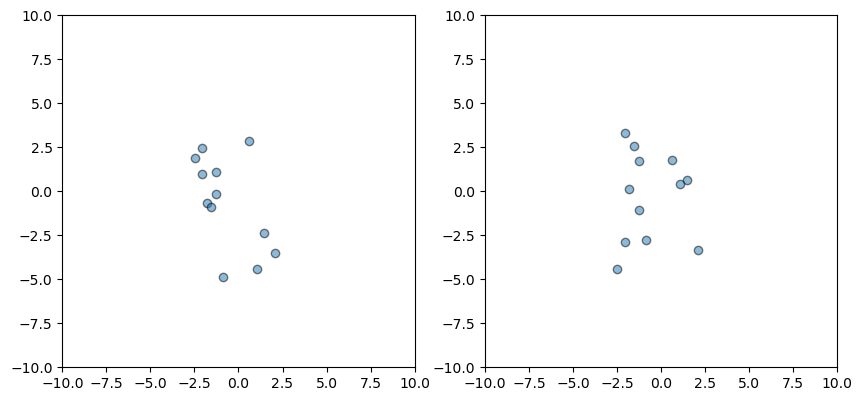

In [33]:
fig,ax = plt.subplots(1,2, figsize=(10,5))
ax[0].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[1].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[0].scatter(snapshot.particles.position[:,0],snapshot.particles.position[:,1], marker="o",alpha=0.5, ec="k")
ax[1].scatter(snapshot.particles.position[:,0],snapshot.particles.position[:,2], marker="o",alpha=0.5, ec="k")

In [34]:
# Apply the harmonic potential on the bonds.
harmonic = hoomd.md.bond.Harmonic()
harmonic.params['A-A'] = dict(k=100, r0=1.0)

# Perform the MD simulation.
sim = hoomd.Simulation(device=hoomd.device.GPU(), seed=1, )
# sim = hoomd.Simulation(device=hoomd.device.CPU(), seed=1, )
sim.create_state_from_gsd(filename='molecular.gsd')
langevin = hoomd.md.methods.Langevin(filter=hoomd.filter.All(), kT=1.0)
langevin.gamma["A"] = 10

integrator = hoomd.md.Integrator(dt=0.005,
                                 methods=[langevin],
                                 forces=[vbc])
gsd_writer = hoomd.write.GSD(filename='molecular_trajectory.gsd',
                             trigger=hoomd.trigger.Periodic(1000),
                             mode='wb')
sim.operations.integrator = integrator
sim.operations.writers.append(gsd_writer)

In [50]:
# %%time
sim.run(2)
gsd_writer.flush()

s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0.000000
s_phi_ab init: 0

In [17]:
sim.run(1)


In [18]:
list(nlist.r_cut.values())

[0.0]

In [19]:
traj = gsd.hoomd.open("molecular_trajectory.gsd", 'r')

In [20]:
len(traj)

0

In [21]:
idx = 1
with nlist.cpu_local_nlist_arrays as arrays:
    nbrs = np.array(arrays.nlist[arrays.head_list[idx]:arrays.head_list[idx]+arrays.n_neigh[idx]])
print(nbrs) 

[]


In [22]:
traj[-1].particles.position

IndexError: 

In [82]:
# new_snap = traj[0]

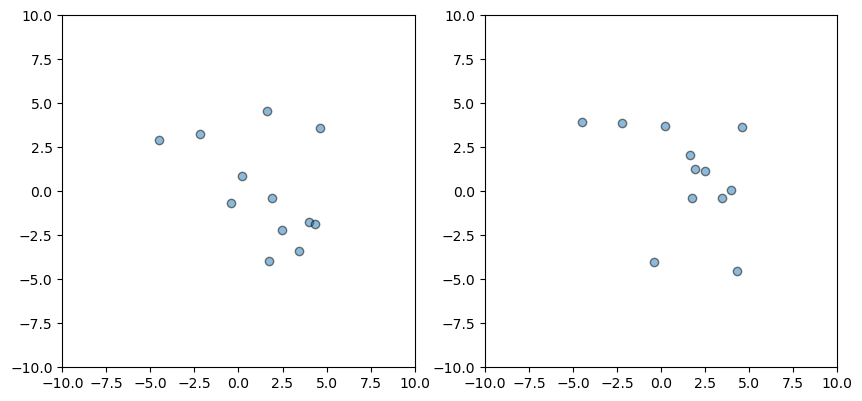

In [83]:
new_snap = traj[-1]
fig,ax = plt.subplots(1,2, figsize=(10,5))
ax[0].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[1].set(aspect=1, xlim=(-10,10),ylim=(-10,10))
ax[0].scatter(new_snap.particles.position[:,0],new_snap.particles.position[:,1], marker="o",alpha=0.5, ec="k")
ax[1].scatter(new_snap.particles.position[:,0],new_snap.particles.position[:,2], marker="o",alpha=0.5, ec="k")